In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
project_root = Path.cwd()
if not (project_root / "data" / "raw" / "hotels.csv").exists():
    project_root = project_root.parent

df = pd.read_csv(project_root / "data" / "raw" / "hotels.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
print("Shape:", df.shape)
print("Canceled:", df["is_canceled"].sum())
print("Cancellation rate:", round(df["is_canceled"].mean() * 100, 2))

Shape: (119390, 32)
Canceled: 44224
Cancellation rate: 37.04


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [9]:
columns = ["children", "agent", "company", "country"]
df[columns].isna().sum()

children         4
agent        16340
company     112593
country        488
dtype: int64

In [10]:
df.shape[0]  # Total rows
df.shape[1]  # Total columns

32

In [11]:
zero_guest = (df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)

print("Zero-guest bookings:", zero_guest.sum())
print("Negative ADR:", (df["adr"] < 0).sum())
print("Maximum ADR:", df["adr"].max())

Zero-guest bookings: 180
Negative ADR: 1
Maximum ADR: 5400.0


In [12]:
valid_status = (
    ((df["is_canceled"] == 0) & (df["reservation_status"] == "Check-Out")) |
    ((df["is_canceled"] == 1) & df["reservation_status"].isin(["Canceled", "No-Show"]))
)

print("Invalid cancellation flags:", (~df["is_canceled"].isin([0, 1])).sum())
print("Status mismatches:", (~valid_status).sum())

Invalid cancellation flags: 0
Status mismatches: 0


# EDA

In [13]:
channel_summary = df.groupby("distribution_channel")["is_canceled"].agg(
    bookings="count",
    canceled="sum",
    cancellation_rate="mean")

channel_summary["cancellation_rate"] = (channel_summary["cancellation_rate"] * 100).round(2)
channel_summary = channel_summary.sort_values("cancellation_rate", ascending=False)
channel_summary

,bookings,canceled,cancellation_rate
distribution_channel,,,
Undefined,5,4,80.00
TA/TO,97870,40152,41.03
Corporate,6677,1474,22.08
GDS,193,37,19.17
Direct,14645,2557,17.46


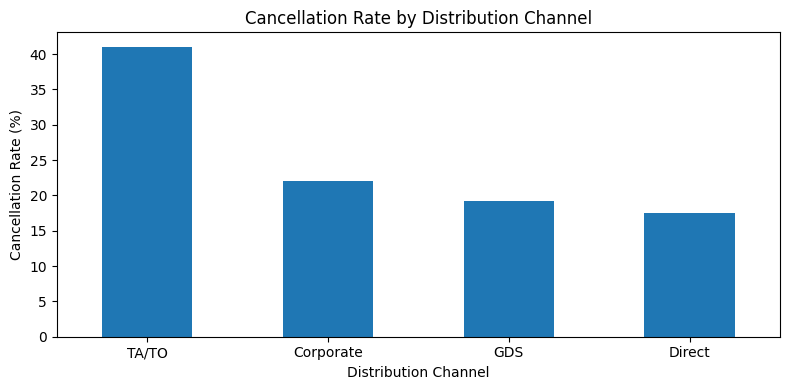

In [14]:
channel_summary.loc[channel_summary["bookings"] >= 100, "cancellation_rate"].plot(
    kind="bar", figsize=(8, 4))
plt.title("Cancellation Rate by Distribution Channel")
plt.xlabel("Distribution Channel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
df["lead_time_bucket"] = pd.cut(
    df["lead_time"],
    bins=[-1, 30, 90, float("inf")],
    labels=["0-30 days", "31-90 days", "91+ days"])

In [16]:
lead_summary = df.groupby("lead_time_bucket", observed=True)["is_canceled"].agg(
    bookings="size",
    canceled="sum",
    cancellation_rate="mean")

lead_summary["cancellation_rate"] = (lead_summary["cancellation_rate"] * 100).round(2)
lead_summary

,bookings,canceled,cancellation_rate
lead_time_bucket,,,
0-30 days,38706,7185,18.56
31-90 days,29553,11141,37.70
91+ days,51131,25898,50.65


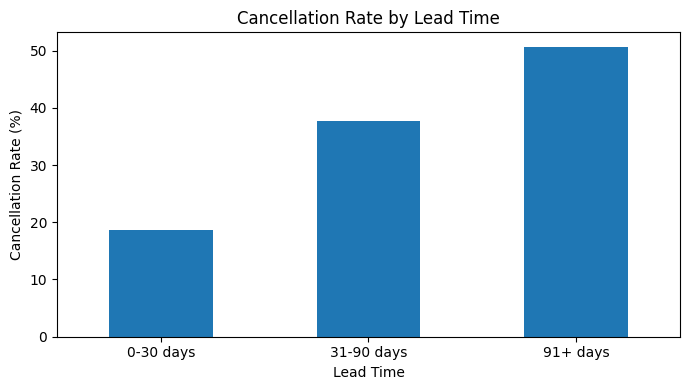

In [17]:
lead_summary["cancellation_rate"].plot(kind="bar", figsize=(7, 4))

plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:

hotel_lead = df.groupby(["lead_time_bucket", "hotel"], observed=True)["is_canceled"].agg(
    bookings="size",
    canceled="sum",
    cancellation_rate="mean")

hotel_lead["cancellation_rate"] = (hotel_lead["cancellation_rate"] * 100).round(2)
hotel_lead


bookings  canceled  cancellation_rate
lead_time_bucket hotel                                              
0-30 days        City Hotel       23362      5199              22.25
                 Resort Hotel     15344      1986              12.94
31-90 days       City Hotel       20797      8300              39.91
                 Resort Hotel      8756      2841              32.45
91+ days         City Hotel       35171     19603              55.74
                 Resort Hotel     15960      6295              39.44

In [19]:

hotel_lead[["bookings", "canceled"]].sum()


bookings    119390
canceled     44224
dtype: int64

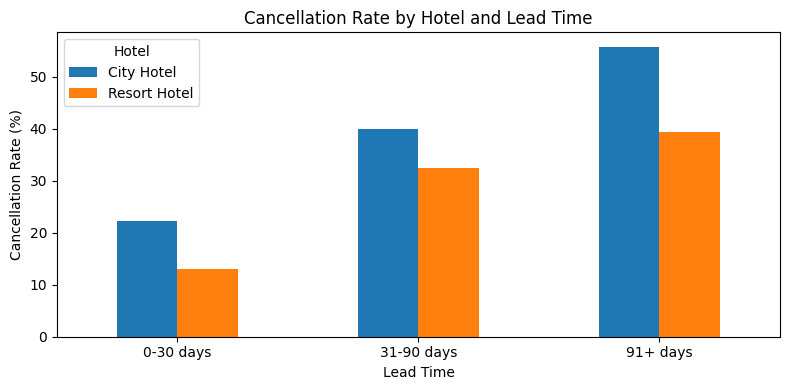

In [20]:

hotel_lead["cancellation_rate"].unstack("hotel").plot(kind="bar", figsize=(8, 4))

plt.title("Cancellation Rate by Hotel and Lead Time")
plt.xlabel("Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Hotel")
plt.tight_layout()
plt.show()


In [21]:

fair = df[df["distribution_channel"].isin(["Direct", "TA/TO"])]

fair_groups = fair.groupby(["hotel", "lead_time_bucket", "distribution_channel"], observed=True).agg(
    bookings=("is_canceled", "size"),
    canceled=("is_canceled", "sum")).reset_index()

fair_groups["cancellation_rate"] = fair_groups["canceled"] / fair_groups["bookings"]
fair_groups


,hotel,lead_time_bucket,distribution_channel,bookings,canceled,cancellation_rate
0,City Hotel,0-30 days,Direct,3999,548,0.137034
1,City Hotel,0-30 days,TA/TO,16714,4212,0.252004
2,City Hotel,31-90 days,Direct,1297,303,0.233616
3,City Hotel,31-90 days,TA/TO,18893,7712,0.408194
4,City Hotel,91+ days,Direct,1484,381,0.256739
5,City Hotel,91+ days,TA/TO,33338,19119,0.573490
6,Resort Hotel,0-30 days,Direct,4231,426,0.100685
7,Resort Hotel,0-30 days,TA/TO,8946,1323,0.147887
8,Resort Hotel,31-90 days,Direct,1466,294,0.200546
9,Resort Hotel,31-90 days,TA/TO,6806,2361,0.346900


In [22]:

print("Groups:", len(fair_groups))
print("Bookings:", fair_groups["bookings"].sum())
print("Canceled:", fair_groups["canceled"].sum())


Groups: 12
Bookings: 112515
Canceled: 42709


In [23]:
fair_groups["pooled_bookings"] = fair_groups.groupby(
    ["hotel", "lead_time_bucket"], observed=True
)["bookings"].transform("sum")

fair_groups["common_weight"] = fair_groups["pooled_bookings"] / fair_groups["bookings"].sum()

fair_groups

,hotel,lead_time_bucket,distribution_channel,bookings,canceled,cancellation_rate,pooled_bookings,common_weight
0,City Hotel,0-30 days,Direct,3999,548,0.137034,20713,0.184091
1,City Hotel,0-30 days,TA/TO,16714,4212,0.252004,20713,0.184091
2,City Hotel,31-90 days,Direct,1297,303,0.233616,20190,0.179443
3,City Hotel,31-90 days,TA/TO,18893,7712,0.408194,20190,0.179443
4,City Hotel,91+ days,Direct,1484,381,0.256739,34822,0.309488
5,City Hotel,91+ days,TA/TO,33338,19119,0.573490,34822,0.309488
6,Resort Hotel,0-30 days,Direct,4231,426,0.100685,13177,0.117113
7,Resort Hotel,0-30 days,TA/TO,8946,1323,0.147887,13177,0.117113
8,Resort Hotel,31-90 days,Direct,1466,294,0.200546,8272,0.073519
9,Resort Hotel,31-90 days,TA/TO,6806,2361,0.346900,8272,0.073519


In [24]:
fair_groups["weighted_rate"] = fair_groups["cancellation_rate"] * fair_groups["common_weight"]

standardized = fair_groups.groupby("distribution_channel")["weighted_rate"].sum() * 100

standardized.round(2)

distribution_channel
Direct    21.12
TA/TO     39.61
Name: weighted_rate, dtype: float64

In [25]:
raw_rates = fair.groupby("distribution_channel")["is_canceled"].mean() * 100

comparison = pd.DataFrame({
    "Raw": raw_rates,
    "Standardized": standardized})

comparison.round(2)

,Raw,Standardized
distribution_channel,,
Direct,17.46,21.12
TA/TO,41.03,39.61


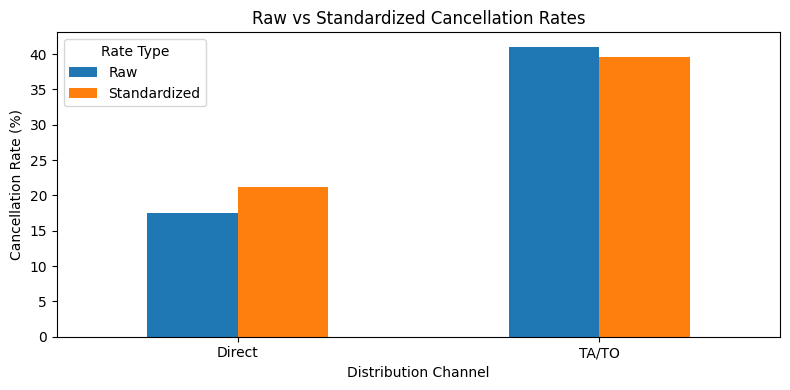

In [26]:
comparison.plot(kind="bar", figsize=(8, 4))

plt.title("Raw vs Standardized Cancellation Rates")
plt.xlabel("Distribution Channel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Rate Type")
plt.tight_layout()
plt.show()

In [27]:
raw_gap = raw_rates["TA/TO"] - raw_rates["Direct"]
standardized_gap = standardized["TA/TO"] - standardized["Direct"]

print("Raw gap:", round(raw_gap, 2), "pp")
print("Standardized gap:", round(standardized_gap, 2), "pp")
print("Gap reduction:", round(raw_gap - standardized_gap, 2), "pp")

Raw gap: 23.57 pp
Standardized gap: 18.49 pp
Gap reduction: 5.07 pp


In [28]:
sensitivity = df[(~zero_guest) & df["distribution_channel"].isin(["Direct", "TA/TO"])]

print("Bookings:", len(sensitivity))

Bookings: 112361


In [29]:
scenario = sensitivity.groupby(
    ["hotel", "lead_time_bucket", "distribution_channel"], observed=True
)["is_canceled"].agg(bookings="size", canceled="sum").reset_index()

scenario["rate"] = scenario["canceled"] / scenario["bookings"]
scenario["pooled_bookings"] = scenario.groupby(
    ["hotel", "lead_time_bucket"], observed=True
)["bookings"].transform("sum")

scenario["weight"] = scenario["pooled_bookings"] / scenario["bookings"].sum()
scenario["weighted_rate"] = scenario["rate"] * scenario["weight"]

In [30]:
scenario_rates = scenario.groupby("distribution_channel")["weighted_rate"].sum() * 100

scenario_gap = scenario_rates["TA/TO"] - scenario_rates["Direct"]

print(scenario_rates.round(2))
print("Original gap:", round(standardized_gap, 2), "pp")
print("Scenario gap:", round(scenario_gap, 2), "pp")
print("Gap change:", round(scenario_gap - standardized_gap, 2), "pp")

distribution_channel
Direct    21.16
TA/TO     39.64
Name: weighted_rate, dtype: float64
Original gap: 18.49 pp
Scenario gap: 18.48 pp
Gap change: -0.01 pp


In [31]:
no_negative_adr = df[(df["adr"] >= 0) | df["adr"].isna()]
no_extreme_adr = df[(df["adr"] != 5400) | df["adr"].isna()]

print("Without negative ADR:")
print(len(no_negative_adr), no_negative_adr["is_canceled"].sum(),
      round(no_negative_adr["is_canceled"].mean() * 100, 2))

print("Without extreme ADR:")
print(len(no_extreme_adr), no_extreme_adr["is_canceled"].sum(),
      round(no_extreme_adr["is_canceled"].mean() * 100, 2))

Without negative ADR:
119389 44224 37.04
Without extreme ADR:
119389 44223 37.04


In [32]:
unique_patterns = df.drop_duplicates()

print("Rows in repeated patterns:", df.duplicated(keep=False).sum())
print("Extra repeated rows:", df.duplicated().sum())
print("One-per-pattern bookings:", len(unique_patterns))
print("One-per-pattern cancellations:", unique_patterns["is_canceled"].sum())
print("One-per-pattern rate:", round(unique_patterns["is_canceled"].mean() * 100, 2))

Rows in repeated patterns: 40165
Extra repeated rows: 31994
One-per-pattern bookings: 87396
One-per-pattern cancellations: 24025
One-per-pattern rate: 27.49


In [33]:

for name, data in [("No negative ADR", no_negative_adr), ("No extreme ADR", no_extreme_adr)]:
    groups = data[data["distribution_channel"].isin(["Direct", "TA/TO"])].groupby(
        ["hotel", "lead_time_bucket", "distribution_channel"], observed=True
    )["is_canceled"].agg(bookings="size", canceled="sum").reset_index()

    groups["weight"] = groups.groupby(
        ["hotel", "lead_time_bucket"], observed=True
    )["bookings"].transform("sum") / groups["bookings"].sum()

    groups["weighted_rate"] = groups["canceled"] / groups["bookings"] * groups["weight"]
    rates = groups.groupby("distribution_channel")["weighted_rate"].sum() * 100

    gap = rates["TA/TO"] - rates["Direct"]
    print(name, rates.round(2).to_dict(), "Gap:", round(gap, 2), "pp")


No negative ADR {'Direct': 21.12, 'TA/TO': 39.61} Gap: 18.49 pp
No extreme ADR {'Direct': 21.12, 'TA/TO': 39.61} Gap: 18.49 pp


In [34]:

analysis_df = df.copy()

analysis_df["zero_guest_flag"] = zero_guest.astype(int)
analysis_df["adr_negative_flag"] = (analysis_df["adr"] < 0).astype(int)
analysis_df["reservation_status_date"] = pd.to_datetime(analysis_df["reservation_status_date"])

print(analysis_df.shape)
print("Zero guests:", analysis_df["zero_guest_flag"].sum())
print("Negative ADR:", analysis_df["adr_negative_flag"].sum())


(119390, 35)
Zero guests: 180
Negative ADR: 1


In [35]:
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

analysis_df.to_csv(output_dir / "hotel_bookings_analysis.csv", index=False)
fair_groups.to_csv(output_dir / "fair_channel_groups.csv", index=False)

comparison.rename(columns={
    "Raw": "raw_rate_pct",
    "Standardized": "standardized_rate_pct"
}).rename_axis("distribution_channel").reset_index().to_csv(
    output_dir / "channel_comparison.csv", index=False)

print("All 3 CSV files exported")


All 3 CSV files exported


In [36]:

results = [
    ["Original", standardized["Direct"], standardized["TA/TO"]],
    ["No zero guests", scenario_rates["Direct"], scenario_rates["TA/TO"]]
]

for name, data in [("No negative ADR", no_negative_adr), ("No extreme ADR", no_extreme_adr)]:
    groups = data[data["distribution_channel"].isin(["Direct", "TA/TO"])].groupby(
        ["hotel", "lead_time_bucket", "distribution_channel"], observed=True
    )["is_canceled"].agg(bookings="size", canceled="sum").reset_index()

    pooled = groups.groupby(["hotel", "lead_time_bucket"], observed=True)["bookings"].transform("sum")
    groups["weighted_rate"] = groups["canceled"] / groups["bookings"] * pooled / groups["bookings"].sum()

    rates = groups.groupby("distribution_channel")["weighted_rate"].sum() * 100
    results.append([name, rates["Direct"], rates["TA/TO"]])

sensitivity_table = pd.DataFrame(results, columns=["scenario", "direct_pct", "ta_to_pct"])
sensitivity_table["gap_pp"] = sensitivity_table["ta_to_pct"] - sensitivity_table["direct_pct"]

scenarios = [df, df.loc[~zero_guest], no_negative_adr, no_extreme_adr]
sensitivity_table["rows_removed_all"] = [len(df) - len(data) for data in scenarios]
sensitivity_table["rows_removed_fair"] = [
    len(fair) - data["distribution_channel"].isin(["Direct", "TA/TO"]).sum()
    for data in scenarios
]

sensitivity_table.round(2)


,scenario,direct_pct,ta_to_pct,gap_pp
0,Original,21.12,39.61,18.49
1,No zero guests,21.16,39.64,18.48
2,No negative ADR,21.12,39.61,18.49
3,No extreme ADR,21.12,39.61,18.49


In [37]:

sensitivity_table.to_csv(output_dir / "sensitivity_summary.csv", index=False)

print("Sensitivity summary exported.")


Sensitivity summary exported.
